# Forecasting HDB Resale Prices: 6 and 12 Months Ahead

**Question:** what will the typical (median) HDB resale price be over the next 6 and 12 months?

We will:
1. Load the latest HDB resale data and turn it into one **monthly time series**.
2. Try two families of forecasting methods:
   - **Statistical time-series models:** Naive, Drift, Holt (ETS), Holt-Winters, SARIMA
   - **Machine-learning models:** Linear Regression, Random Forest, Gradient Boosting (using lag features)
3. **Backtest** every method: pretend we are in the past, forecast 12 months, and compare with what really happened.
4. Pick the method with the smallest error and **save it** for the Streamlit app (`app.py`).

> Run `python download_data.py` first to get the latest data into `data/hdb_resale.csv`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

warnings.filterwarnings("ignore")   # statsmodels prints many convergence notes
plt.rcParams["figure.figsize"] = (11, 4)

## 1. Load the data and build a monthly series

Each row is one resale transaction. We want **one number per month**: the median resale price.
We use the median (not the mean) because a few very expensive flats would pull the mean up.

The newest month in the file is usually still being filled (sales are registered over the month),
so we drop the current calendar month.

In [2]:
df = pd.read_csv("data/hdb_resale.csv")
df["month"] = pd.to_datetime(df["month"])

this_month = pd.Timestamp.today().to_period("M").to_timestamp()
df = df[df["month"] < this_month]          # drop the incomplete current month

series = df.groupby("month")["resale_price"].median()
series.index.freq = "MS"                    # MS = monthly, dated at the month start
series.name = "median_price"

print(f"{len(df):,} transactions, {len(series)} months: "
      f"{series.index[0]:%b %Y} to {series.index[-1]:%b %Y}")
series.tail()

241,698 transactions, 117 months: Jan 2017 to Sep 2026


month
2026-05-01    630000.0
2026-06-01    625000.0
2026-07-01    630000.0
2026-08-01    635000.0
2026-09-01    650000.0
Freq: MS, Name: median_price, dtype: float64

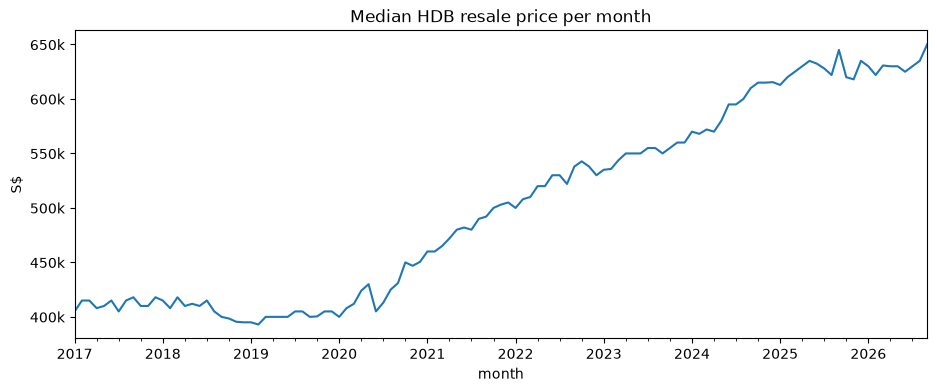

In [3]:
ax = series.plot(title="Median HDB resale price per month", ylabel="S$")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
plt.show()

**What do we see?**
- A clear **upward trend**, especially since 2020.
- No strong repeating yearly (seasonal) pattern. Seasonality is small compared with the trend.

A good forecaster must follow the trend. Methods that assume prices stay flat will do badly.

## 2. The forecasting methods

Every method below is written as a function with the same shape:

```python
forecast_xxx(train, h)  ->  array of h future values
```

`train` is the history we are allowed to see, and `h` is how many months to forecast (here 12).
The same shape lets us test all methods in one loop.

### 2a. Statistical time-series models

| Method | Idea |
|---|---|
| **Naive** | Next months = last month's value. The baseline every model must beat. |
| **Drift** | Draw a straight line from the first to the last point and extend it. |
| **Holt (ETS)** | Exponential smoothing with a level and a (damped) trend. Recent months count more. |
| **Holt-Winters** | Holt, plus a repeating 12-month seasonal pattern. |
| **SARIMA** | Models each month from previous months and previous errors, with yearly seasonality. |

In [4]:
def forecast_naive(train, h):
    return np.repeat(train.iloc[-1], h)


def forecast_drift(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)


def forecast_holt(train, h):
    fit = ExponentialSmoothing(train, trend="add", damped_trend=True).fit()
    return fit.forecast(h).values


def forecast_holt_winters(train, h):
    fit = ExponentialSmoothing(train, trend="add", damped_trend=True,
                               seasonal="add", seasonal_periods=12).fit()
    return fit.forecast(h).values


def forecast_sarima(train, h):
    fit = SARIMAX(train, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    return fit.forecast(h).values

### 2b. Machine-learning models with lag features

ML models need a table of **features (X)** and a **target (y)**. A time series has neither,
so we build them with **lags**: to predict month *t* we use the values of the previous 12 months.

**One important trick:** tree models (Random Forest, Gradient Boosting) **cannot predict a value
higher than anything they saw in training**. Prices keep rising, so a tree trained on price
levels would flatten out. Instead we train every ML model on the **monthly change**
(this month minus last month) and add the predicted changes back onto the last known price.

To forecast 12 months, we predict one month, append the prediction to the history, and repeat.
This is called **recursive forecasting**.

In [5]:
N_LAGS = 12


def make_lag_table(changes, n_lags=N_LAGS):
    """Each row: the previous n_lags monthly changes (X) and the next change (y)."""
    X = np.array([changes[i - n_lags:i] for i in range(n_lags, len(changes))])
    y = changes[n_lags:]
    return X, y


def fit_ml(model, train):
    changes = train.diff().dropna().values
    X, y = make_lag_table(changes)
    return model.fit(X, y)


def recursive_forecast(model, last_price, last_changes, h):
    """Predict one month at a time, feeding each prediction back in as a lag."""
    changes, price, preds = list(last_changes), last_price, []
    for _ in range(h):
        next_change = model.predict([changes[-N_LAGS:]])[0]
        changes.append(next_change)
        price += next_change
        preds.append(price)
    return np.array(preds)


def make_ml_forecaster(make_model):
    def forecast(train, h):
        model = fit_ml(make_model(), train)
        last_changes = train.diff().dropna().values[-N_LAGS:]
        return recursive_forecast(model, train.iloc[-1], last_changes, h)
    return forecast


# A peek at the lag table the ML models learn from
X_demo, y_demo = make_lag_table(series.diff().dropna().values)
pd.DataFrame(X_demo, columns=[f"change_lag_{N_LAGS - i}" for i in range(N_LAGS)]).assign(target_next_change=y_demo).tail(3).round(0)

,change_lag_12,change_lag_11,change_lag_10,change_lag_9,change_lag_8,change_lag_7,change_lag_6,change_lag_5,change_lag_4,change_lag_3,change_lag_2,change_lag_1,target_next_change
101,-4400.0,-6000.0,23000.0,-25000.0,-2000.0,17000.0,-5000.0,-8000.0,8750.0,-750.0,0.0,-5000.0,5000.0
102,-6000.0,23000.0,-25000.0,-2000.0,17000.0,-5000.0,-8000.0,8750.0,-750.0,0.0,-5000.0,5000.0,5000.0
103,23000.0,-25000.0,-2000.0,17000.0,-5000.0,-8000.0,8750.0,-750.0,0.0,-5000.0,5000.0,5000.0,15000.0


In [6]:
METHODS = {
    "Naive":             forecast_naive,
    "Drift":             forecast_drift,
    "Holt (ETS)":        forecast_holt,
    "Holt-Winters":      forecast_holt_winters,
    "SARIMA":            forecast_sarima,
    "Linear Regression": make_ml_forecaster(LinearRegression),
    "Random Forest":     make_ml_forecaster(lambda: RandomForestRegressor(n_estimators=300, random_state=42)),
    "Gradient Boosting": make_ml_forecaster(lambda: GradientBoostingRegressor(random_state=42)),
}

## 3. A first look: forecast the last 12 months

We hide the most recent 12 months, train on everything before, and forecast those 12 months.

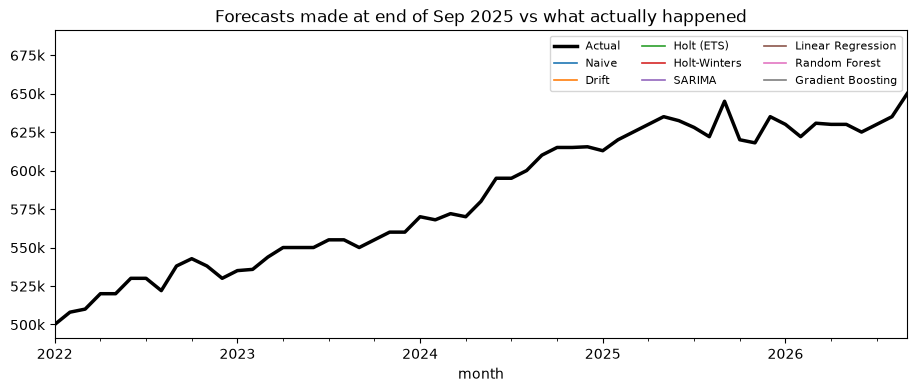

In [7]:
HORIZON = 12
train, test = series[:-HORIZON], series[-HORIZON:]

fig, ax = plt.subplots()
actual = series["2022":]
ax.plot(actual.index, actual.values, color="black", lw=2.5, label="Actual")   # ax.plot, not series.plot: keeps one date axis for all lines
for name, forecast in METHODS.items():
    ax.plot(test.index, forecast(train, HORIZON), lw=1.2, label=name)
ax.axvline(test.index[0], color="grey", ls=":")
ax.set_title(f"Forecasts made at end of {train.index[-1]:%b %Y} vs what actually happened")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
ax.legend(ncol=3, fontsize=8)
plt.show()

## 4. Backtest: compare methods fairly

One test window can be lucky or unlucky, so we repeat the experiment from **three different
starting points** (forecast origins), each 6 months apart, and average the errors.

For each forecast we measure two horizons:
- **6-month error:** how wrong the first 6 forecast months were
- **12-month error:** how wrong all 12 forecast months were

We report **MAE** (average error in S$) and **MAPE** (average error as % of the true price).

In [8]:
ORIGINS = [len(series) - HORIZON - 6 * k for k in (2, 1, 0)]   # three cut-off points

rows = []
for cut in ORIGINS:
    train, test = series[:cut], series[cut:cut + HORIZON]
    for name, forecast in METHODS.items():
        err = np.abs(forecast(train, HORIZON) - test.values)
        pct = err / test.values * 100
        rows.append({"method": name, "origin": f"{train.index[-1]:%b %Y}",
                     "MAE_6m": err[:6].mean(), "MAE_12m": err.mean(),
                     "MAPE_6m": pct[:6].mean(), "MAPE_12m": pct.mean()})

backtest = pd.DataFrame(rows)
print("Forecast origins:", backtest["origin"].unique())

results = (backtest.groupby("method")[["MAE_6m", "MAE_12m", "MAPE_6m", "MAPE_12m"]]
           .mean().sort_values("MAPE_12m"))
results.style.format({"MAE_6m": "S${:,.0f}", "MAE_12m": "S${:,.0f}",
                      "MAPE_6m": "{:.2f}%", "MAPE_12m": "{:.2f}%"}).highlight_min(color="#c6efce")

Forecast origins: <ArrowStringArray>
['Sep 2024', 'Mar 2025', 'Sep 2025']
Length: 3, dtype: str


,MAE_6m,MAE_12m,MAPE_6m,MAPE_12m
method,,,,
Naive,"S$11,443","S$12,615",1.83%,2.00%
Drift,"S$11,763","S$15,957",1.88%,2.54%
Random Forest,"S$12,013","S$17,355",1.93%,2.77%
Holt-Winters,"S$11,005","S$18,625",1.76%,2.97%
Holt (ETS),"S$12,114","S$19,359",1.94%,3.09%
Linear Regression,"S$12,901","S$19,510",2.07%,3.11%
Gradient Boosting,"S$15,945","S$21,122",2.55%,3.37%
SARIMA,"S$16,250","S$24,295",2.60%,3.87%


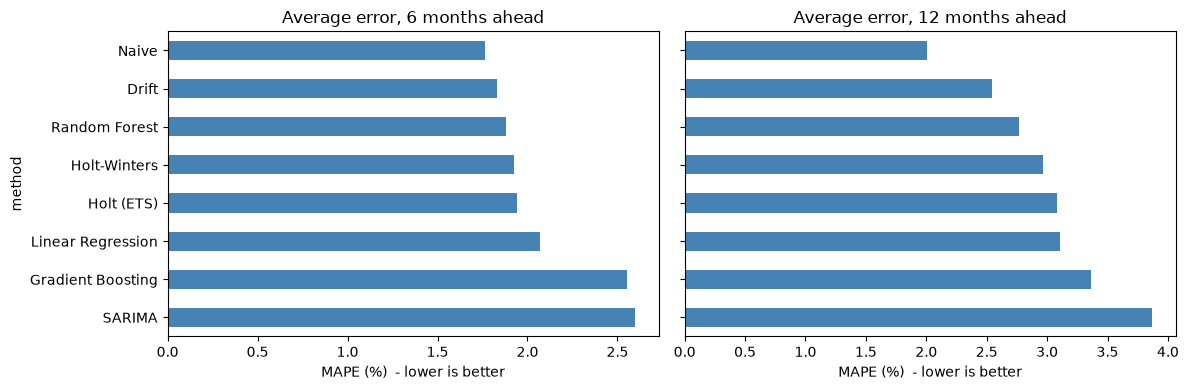

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, title in zip(axes, ["MAPE_6m", "MAPE_12m"], ["6 months ahead", "12 months ahead"]):
    results[col].sort_values(ascending=False).plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"Average error, {title}")
    ax.set_xlabel("MAPE (%)  - lower is better")
plt.tight_layout()
plt.show()

### What the backtest tells us

*(Numbers below are from the data snapshot up to Sep 2026. Re-running with newer data may change the ranking. That is the point of backtesting.)*

- **The simple Naive baseline wins at 12 months** (about 2.0% error, roughly S$12.6k).
  Prices rose fast from 2020 to 2024 and then **levelled off in 2025-2026**.
  Methods that learned the old upward trend (Drift, Holt, SARIMA, the ML models) kept forecasting
  increases that did not happen.
- **At 6 months the methods are much closer** (all about 1.8-2.6%), and Holt-Winters is narrowly best.
  The further ahead we forecast, the more a wrong trend assumption hurts.
- **Random Forest is the best ML model.** But lag features alone do not give it information
  about *why* the market changed (policy, supply, interest rates).
- **Lesson:** a fancy model is not automatically better. When the future does not look like the past,
  the honest baseline is hard to beat. We deploy whichever method wins the backtest, even if it is the simple one.

## 5. Pick the winner and forecast the real future

We choose the method with the **lowest 12-month MAPE**, retrain it on **all** the data,
and forecast the next 12 months.

Best method: Naive
Typical error: 1.8% at 6 months, 2.0% at 12 months


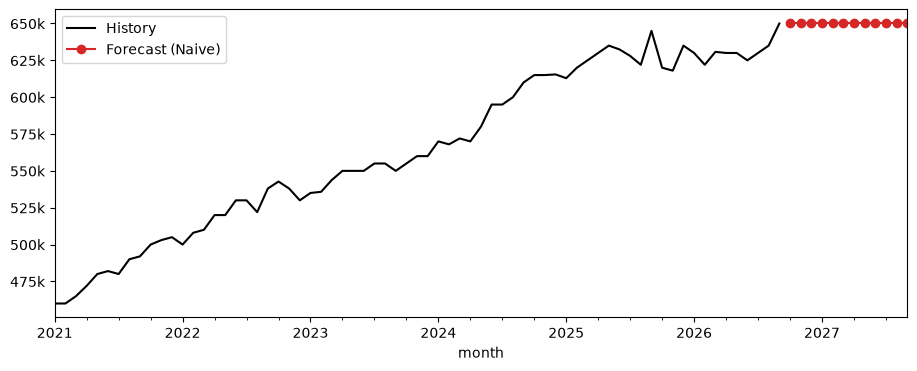

,forecast
2027-03-01,"S$650,000"
2027-09-01,"S$650,000"


In [10]:
best_name = results["MAPE_12m"].idxmin()
print("Best method:", best_name)
print(f"Typical error: {results.loc[best_name, 'MAPE_6m']:.1f}% at 6 months, "
      f"{results.loc[best_name, 'MAPE_12m']:.1f}% at 12 months")

future_index = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(), periods=HORIZON, freq="MS")
future = pd.Series(METHODS[best_name](series, HORIZON), index=future_index)

fig, ax = plt.subplots()
series["2021":].plot(ax=ax, color="black", label="History")
future.plot(ax=ax, color="tab:red", marker="o", label=f"Forecast ({best_name})")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
ax.legend()
plt.show()

future.iloc[[5, 11]].map("S${:,.0f}".format).rename("forecast").to_frame()

## 6. Save the model for the Streamlit app

The app should not retrain anything. It loads a saved file and forecasts.
So we save the **fitted model itself** plus what it needs to forecast:

- statistical models: the fitted statsmodels result (it knows how to `.forecast(h)`)
- ML models: the trained sklearn model, the last price and the last 12 monthly changes
- Naive / Drift: just the last price and the slope

We also save the history and the backtest table so the app can show them.

In [11]:
def build_bundle(name, series):
    bundle = {"method": name, "history": series, "results": results,
              "last_price": float(series.iloc[-1])}
    if name in ("Naive", "Drift"):
        slope = 0.0 if name == "Naive" else (series.iloc[-1] - series.iloc[0]) / (len(series) - 1)
        bundle.update(kind="drift", slope=float(slope))
    elif name == "Holt (ETS)":
        bundle.update(kind="stats", model=ExponentialSmoothing(series, trend="add", damped_trend=True).fit())
    elif name == "Holt-Winters":
        bundle.update(kind="stats", model=ExponentialSmoothing(series, trend="add", damped_trend=True,
                                                               seasonal="add", seasonal_periods=12).fit())
    elif name == "SARIMA":
        bundle.update(kind="stats", model=SARIMAX(series, order=(1, 1, 1),
                                                  seasonal_order=(0, 1, 1, 12)).fit(disp=False))
    else:
        make_model = {"Linear Regression": LinearRegression,
                      "Random Forest": lambda: RandomForestRegressor(n_estimators=300, random_state=42),
                      "Gradient Boosting": lambda: GradientBoostingRegressor(random_state=42)}[name]
        bundle.update(kind="ml", model=fit_ml(make_model(), series), n_lags=N_LAGS,
                      last_changes=series.diff().dropna().values[-N_LAGS:])
    return bundle


bundle = build_bundle(best_name, series)
joblib.dump(bundle, "best_model.pkl")
print(f"Saved best_model.pkl ({best_name}, trained through {series.index[-1]:%b %Y})")

Saved best_model.pkl (Naive, trained through Sep 2026)


Now run the app:

```bash
streamlit run app.py
```

## Key takeaways
- Always compare against a **simple baseline** (Naive). A complex model is only worth it if it beats the baseline.
- **Backtest over several origins.** One test window can mislead.
- Tree-based ML models **cannot extrapolate**. Model the *change*, not the level, when the series trends.
- Error grows with the horizon. A 12-month forecast is always less certain than a 6-month one.